In [35]:
# Required Labreries:
import numpy as np
import pandas as pd
import matplotlib.pyplot as mtb
import seaborn as sb
import sklearn as sl

Exercice 1:Exploring a tabular dataset and creating data splits

In [2]:
# 1: Load the data set in csv format:
D=pd.read_csv("Iris_Dataset.csv")

# 2: Inspect the dataset:
print(D.info())
print("################################################")
print(D.describe())
print("################################################")
print(D.shape)
print("################################################")
print(D.columns)
print("################################################")
print(D.head())
print("################################################")

<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    str    
dtypes: float64(4), str(1)
memory usage: 7.9 KB
None
################################################
       sepal_length  sepal_width  petal_length  petal_width
count    150.000000   150.000000    150.000000   150.000000
mean       5.843333     3.054000      3.758667     1.198667
std        0.828066     0.433594      1.764420     0.763161
min        4.300000     2.000000      1.000000     0.100000
25%        5.100000     2.800000      1.600000     0.300000
50%        5.800000     3.000000      4.350000     1.300000
75%        6.400000     3.300000      5.100000     1.800000
max        7.900000     

Brief Explanation :                                  

info(): shows num of rows and columns , the type and name  of each column and non_null elements and storage space in the memory.                          

desribe(): shows statical mesures about dataset like (mean min max) of each column.                    

shape: shows the dimention of dataset(rows,columns).   

columns: shows a list of columns name and their type.                                                 
head(): returns first 5 rows of dataset.  


In [13]:
# 3: Creat new dataset that contains 2 columns:
ND=D[["sepal_length" , "petal_width"]]

# 4: Display first 20 observations:
print(ND.head(20))

    sepal_length  petal_width
0            5.1          0.2
1            4.9          0.2
2            4.7          0.2
3            4.6          0.2
4            5.0          0.2
5            5.4          0.4
6            4.6          0.3
7            5.0          0.2
8            4.4          0.2
9            4.9          0.1
10           5.4          0.2
11           4.8          0.2
12           4.8          0.1
13           4.3          0.1
14           5.8          0.2
15           5.7          0.4
16           5.4          0.4
17           5.1          0.3
18           5.7          0.3
19           5.1          0.3


In [14]:
# 5: Create a copy of the original dataset:
D_copy=D.copy(deep=True)
D_copy.to_csv("Iris_Dataset_copy.csv",index=False)
print(D_copy.head())

   sepal_length  sepal_width  petal_length  petal_width      species
0           5.1          3.5           1.4          0.2  Iris-setosa
1           4.9          3.0           1.4          0.2  Iris-setosa
2           4.7          3.2           1.3          0.2  Iris-setosa
3           4.6          3.1           1.5          0.2  Iris-setosa
4           5.0          3.6           1.4          0.2  Iris-setosa


We craete a copy because we will make changes ,such as cleaning and splitting the data .if we make mistakes , we can always create a new copy from the original dataset and start again.

In [15]:
# 6/7: Split the data 80% training and 20% test using random_state=42 and stratify=y:
from sklearn.model_selection import train_test_split
# Separate features and target:
X=D.drop(columns=["species"]) 
y=D["species"]
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)

Input features: sepal_length , sepal_width ,petal_length , petal_width.                          
Target feature: species

In [17]:
# 8: verifecation of proportion of observation in the training and test set:
print("Training proportion:",len(X_train)/len(D))
print("Test proportion:",len(X_test)/len(D))

Training proportion: 0.8
Test proportion: 0.2


Discussion:                                         test set should be kept separate until the final evaluation to avoid data leakage.                    
Otherwise , the model may indirectly learn from the test data to overly optimistic results and misleading performence.

Exercice 2: Exploring text data:

In [18]:
# 1: Open the txt_file.txt :
with open("txt_file.txt","r",encoding="utf_8") as file:
    content=file.read()

print(content)

0.50,0.20,0.84,0.01,c1
0.10,0.10,0.40,0.02,c2
0.15,0.10,0.45,0.03,c2
0.22,0.20,0.90,0.01,c1
0.25,0.20,0.87,0.01,c1
0.10,0.10,0.38,0.02,c2



In [19]:
# 2:Iterate through the flie and display each line;remove the trailing new line character:
with open("txt_file.txt","r",encoding="utf_8") as file:
    for line in file:
        print(line.rstrip("\n"))

0.50,0.20,0.84,0.01,c1
0.10,0.10,0.40,0.02,c2
0.15,0.10,0.45,0.03,c2
0.22,0.20,0.90,0.01,c1
0.25,0.20,0.87,0.01,c1
0.10,0.10,0.38,0.02,c2


In [22]:
# 3: Load 20Newspaper dataset starting by training subset:
from sklearn.datasets import fetch_20newsgroups
news_data=fetch_20newsgroups(subset="train")

In [23]:
# 4: Display the number of documents and labels:
print("Number of documents:",len(news_data.data))
print("Number of labels:",len(news_data.target))

Number of documents: 11314
Number of labels: 11314


The numbers of documents and labels are equals because each document has its appropriate label.

In [25]:
# 5:Display the first document and inspect its associated target label:
print(news_data.data[0])
print(news_data.target[0])

From: lerxst@wam.umd.edu (where's my thing)
Subject: WHAT car is this!?
Nntp-Posting-Host: rac3.wam.umd.edu
Organization: University of Maryland, College Park
Lines: 15

 I was wondering if anyone out there could enlighten me on this car I saw
the other day. It was a 2-door sports car, looked to be from the late 60s/
early 70s. It was called a Bricklin. The doors were really small. In addition,
the front bumper was separate from the rest of the body. This is 
all I know. If anyone can tellme a model name, engine specs, years
of production, where this car is made, history, or whatever info you
have on this funky looking car, please e-mail.

Thanks,
- IL
   ---- brought to you by your neighborhood Lerxst ----





7


In [26]:
# 6: Display the avalable class names and their numeric values:
print(news_data.target_names)
for i,name in enumerate(news_data.target_names):
    print(i,":",name)

['alt.atheism', 'comp.graphics', 'comp.os.ms-windows.misc', 'comp.sys.ibm.pc.hardware', 'comp.sys.mac.hardware', 'comp.windows.x', 'misc.forsale', 'rec.autos', 'rec.motorcycles', 'rec.sport.baseball', 'rec.sport.hockey', 'sci.crypt', 'sci.electronics', 'sci.med', 'sci.space', 'soc.religion.christian', 'talk.politics.guns', 'talk.politics.mideast', 'talk.politics.misc', 'talk.religion.misc']
0 : alt.atheism
1 : comp.graphics
2 : comp.os.ms-windows.misc
3 : comp.sys.ibm.pc.hardware
4 : comp.sys.mac.hardware
5 : comp.windows.x
6 : misc.forsale
7 : rec.autos
8 : rec.motorcycles
9 : rec.sport.baseball
10 : rec.sport.hockey
11 : sci.crypt
12 : sci.electronics
13 : sci.med
14 : sci.space
15 : soc.religion.christian
16 : talk.politics.guns
17 : talk.politics.mideast
18 : talk.politics.misc
19 : talk.religion.misc


Each target name has its associated value 

In [28]:
# 7:compare the document lenghts:
lenghts=[len(doc) for doc in news_data.data]
print(lenghts[:10])
print("shortest document:",min(lenghts))
print("longest document:",max(lenghts))

[721, 858, 1981, 815, 1120, 2602, 583, 2834, 318, 1550]
shortest document: 125
longest document: 75154


Exercice 3: Detecting and handling missing values:

In [31]:
data_employee=pd.read_csv("employees.csv")
print(data_employee.columns)
print(data_employee.info())
print(data_employee.head(5))

Index(['First Name', 'Gender', 'Start Date', 'Last Login Time', 'Salary',
       'Bonus %', 'Senior Management', 'Team'],
      dtype='str')
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   First Name         933 non-null    str    
 1   Gender             855 non-null    str    
 2   Start Date         1000 non-null   str    
 3   Last Login Time    1000 non-null   str    
 4   Salary             1000 non-null   int64  
 5   Bonus %            1000 non-null   float64
 6   Senior Management  933 non-null    object 
 7   Team               957 non-null    str    
dtypes: float64(1), int64(1), object(1), str(5)
memory usage: 98.3+ KB
None
  First Name  Gender Start Date Last Login Time  Salary  Bonus %  \
0    Douglas    Male   8/6/1993        12:42 PM   97308    6.945   
1     Thomas    Male  3/31/1996         6:53 AM   61933    4.170   
2    

In [33]:
# 2: Count missing values in each column using isna().sum():
missing_counts=data_employee.isna().sum()
print("missing values in each column is: \n",missing_counts)

missing values in each column is: 
 First Name            67
Gender               145
Start Date             0
Last Login Time        0
Salary                 0
Bonus %                0
Senior Management     67
Team                  43
dtype: int64


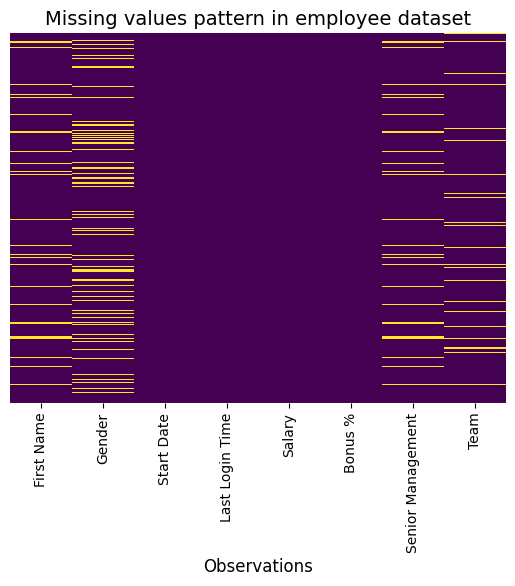

In [34]:
# 3:Visualize missing-value patterns using a seaborn heatmap. Add a title and clear axis labels:
mtb.Figure(figsize=(10, 6))
sb.heatmap(data_employee.isna(),cbar=False,cmap='viridis',yticklabels=False)
mtb.title("Missing values pattern in employee dataset",fontsize=14)
mtb.xlabel("Columns",fontsize=12)
mtb.xlabel("Observations",fontsize=12)
mtb.show()


In [46]:
# 4:Create a copy of the original DataFrame. In the copy, append one synthetic row containing eight fields; set first name 
#to '-' and gender to 'na'.Fill the other fields with suitable missing-value markers, as specified by the dataset structure:

data_copy=data_employee.copy()
synthetic_row={
    'First Name':'-',
    'Gender':'na',
    'Start Date':'N/A',
    'Last Login Time':'',
    'Salary':np.nan,
    'Bonus %':None,
    'Senior Management':'',
    'Team':'unknown'
}
synthetic_df=pd.DataFrame([synthetic_row])
data_copy=pd.concat([data_copy,synthetic_df])

In [47]:
# 5: recount missing values:
print("missing values in each column in the new data is: \n",data_copy.isna().sum())

missing values in each column in the new data is: 
 First Name            67
Gender               145
Start Date             0
Last Login Time        0
Salary                 1
Bonus %                1
Senior Management     67
Team                  43
dtype: int64


Pandas doesn't consider '-','na' to be missing values as None and np.nan unless explicitly told otherwise, therefore it treats them as strings

In [48]:
# 6:Convert the chosen markers ('-', 'na', and any other agreed placeholders) to np.nan:
placeholders=['-','na','N/A','?','','unknown']
data_copy=data_copy.replace(placeholders,np.nan)
print("missing values in each column after replacing by np.nan: \n",data_copy.isna().sum())

missing values in each column after replacing by np.nan: 
 First Name            68
Gender               146
Start Date             1
Last Login Time        1
Salary                 1
Bonus %                1
Senior Management     68
Team                  44
dtype: int64


Now , after replacing them by np.nan Pandas consider them as missing values and the number increament in each column.

In [49]:
# 7:Use sklearn.impute.SimpleImputer to handle missing values:
from sklearn.impute import SimpleImputer
num_col=['Salary','Bonus %']
cate_col=['Gender','Team','Senior Management','Last Login Time','Start Date']
#First name is an identifier so we can't impute it
#impute numerical data using median strategy:
num_imputer=SimpleImputer(strategy='median') 
data_copy[num_col]=num_imputer.fit_transform(data_copy[num_col])
#impute categorical data using modt_frequent strategy:
cat_imputer=SimpleImputer(strategy='most_frequent') 
data_copy[cate_col]=cat_imputer.fit_transform(data_copy[cate_col])

print("missing values are handled succesfuly")

missing values are handled succesfuly


In [50]:
# 8:Compare the missing-value counts before and after preprocessing:
print("Missing values after imputation:")
print(data_copy.isna().sum())

Missing values after imputation:
First Name           68
Gender                0
Start Date            0
Last Login Time       0
Salary                0
Bonus %               0
Senior Management     0
Team                  0
dtype: int64


Limiation of imputation:                                      
Variance Reduction: by replacing missing values by mean or median the data be less variante and  it influence the model performence.                                                  
it can't applied into identifiers.                                
it improves the Bias in the data so in the model.

Exercice 4:Feature scaling, binarization, and categorical encoding

Part A:Scaling and binarization

In [51]:
from sklearn.preprocessing import StandardScaler,MinMaxScaler,MaxAbsScaler,RobustScaler,normalize,Binarizer
M=np.array([[1,-1,2],
            [2,0,0],
            [0,1,-1]])
# 1:MaxScaler, MaxAbsScaler, RobustScaler, and normalize from scikit-learn to the matrix. 
scaler_std=StandardScaler()
M_std=scaler_std.fit_transform(M)

scaler_minmax=MinMaxScaler()
M_minmax=scaler_minmax.fit_transform(M)

scaler_robust=RobustScaler()
M_robust=scaler_robust.fit_transform(M)

scaler_maxabs=MaxAbsScaler()
M_maxabs=scaler_maxabs.fit_transform(M)

M_normalized=normalize(M,norm='l2')

In [52]:
# 2:Display the transformed matrix for each method and compare the results:
print("---StandardScaler---\n",np.round(M_std,2))
print("---MinMaxScaler---\n",np.round(M_minmax,2))
print("---RobustScaler---\n",np.round(M_robust,2))
print("---MaxAbsScaler---\n",np.round(M_maxabs,2))
print("---normalize(L2)---\n",np.round(M_normalized,2))

---StandardScaler---
 [[ 0.   -1.22  1.34]
 [ 1.22  0.   -0.27]
 [-1.22  1.22 -1.07]]
---MinMaxScaler---
 [[0.5  0.   1.  ]
 [1.   0.5  0.33]
 [0.   1.   0.  ]]
---RobustScaler---
 [[ 0.   -1.    1.33]
 [ 1.    0.    0.  ]
 [-1.    1.   -0.67]]
---MaxAbsScaler---
 [[ 0.5 -1.   1. ]
 [ 1.   0.   0. ]
 [ 0.   1.  -0.5]]
---normalize(L2)---
 [[ 0.41 -0.41  0.82]
 [ 1.    0.    0.  ]
 [ 0.    0.71 -0.71]]


StandardScaler centers data to mean 0 with unit variance, while MinMax and MaxAbs restrict values to specific ranges (e.g., 0 to 1).                                               

RobustScaler uses median and IQR, making it resistant to outliers and preserving the data's original shape better.     

Normalize works on rows (samples) to make their vector length equal to 1.                                            

Overall, column-based scalers change the distribution of features, whereas row normalization only alters the direction of each sample.                                             

3 :Main idea of each method and whether it scales features or samples.

Column scalers (Standard, MinMax, MaxAbs, Robust) transform each feature independently to prevent variables with larger ranges from dominating the model.                             

StandardScaler uses mean/std, MinMax uses min/max, MaxAbs uses max absolute value, and Robust uses median/IQR.           

Conversely, Normalize scales each sample (row) individually so its vector norm equals 1, often used in text or spatial data.                                                        

The main idea is ensuring fair feature contribution for distance-based models or speeding up gradient descent.

In [53]:
# 4:Binarize the original matrix using an explicitly stated threshold:
binarizer=Binarizer(threshold=0.5)
M_binarized=binarizer.fit_transform(M)
print("Binarized(threshold=0.5)\n",M_binarized)

Binarized(threshold=0.5)
 [[1 0 1]
 [1 0 0]
 [0 1 0]]


if the threshold chenge the outputs changed because the they depend on thershold value.

Disscusion:                                                    scaling is matter in K-NN SVM because they focus on distence between variables.
Decision tree doesn't matter about scaling because it uses a bondray and makes decisions.

Part B:Encoding categorical variables

In [54]:
# 1:Use OrdinalEncoder to convert the three categorical input features into numeric values. Display the categories_ 
#attribute:
from sklearn.preprocessing import OrdinalEncoder, LabelEncoder, OneHotEncoder

X_cat = np.array([['male', 'from US', 'uses Safari'],
                  ['female', 'from Europe', 'uses Safari'],
                  ['female', 'from Asia', 'uses Firefox'],
                  ['male', 'from Africa', 'uses Chrome']])
y_cat = np.array(['US', 'France', 'Japan', 'Algeria'])

ordinal_enc = OrdinalEncoder()
X_encoded = ordinal_enc.fit_transform(X_cat)

print("Encoded Features:\n", X_encoded)
print("\nCategories:\n", ordinal_enc.categories_)

Encoded Features:
 [[1. 3. 2.]
 [0. 2. 2.]
 [0. 1. 1.]
 [1. 0. 0.]]

Categories:
 [array(['female', 'male'], dtype='<U12'), array(['from Africa', 'from Asia', 'from Europe', 'from US'], dtype='<U12'), array(['uses Chrome', 'uses Firefox', 'uses Safari'], dtype='<U12')]


0 means that the gender is femal and 1 means male no numerical signification here.

In [55]:
# 2:Encode the target variable separately using LabelEncoder or OrdinalEncoder, and display the mapping between class 
#names and numeric labels:
label_enc = LabelEncoder()
y_encoded = label_enc.fit_transform(y_cat)

print("Encoded Target:\n", y_encoded)
print("Target Classes Mapping:\n", label_enc.classes_)

Encoded Target:
 [3 1 2 0]
Target Classes Mapping:
 ['Algeria' 'France' 'Japan' 'US']


In [56]:
# 3:Apply OneHotEncoder to the target variable and display the resulting binary representation:
onehot_enc = OneHotEncoder(sparse_output=False) 
y_onehot = onehot_enc.fit_transform(y_cat.reshape(-1, 1))

print("One-Hot Encoded Target:\n", y_onehot)
print("Feature Names:", onehot_enc.get_feature_names_out())

One-Hot Encoded Target:
 [[0. 0. 0. 1.]
 [0. 1. 0. 0.]
 [0. 0. 1. 0.]
 [1. 0. 0. 0.]]
Feature Names: ['x0_Algeria' 'x0_France' 'x0_Japan' 'x0_US']


the diffrence is that label incoding uses integers for coding categories while one-hot encoding uses binary columns representation.

 disscusion : 
 Label encoding assigns a single integer to each category ,falsely implying an artificial order.Onehot encoding creates separate binary columns treating categories independently without any false hierarchy. 